# Smart Supply Chain Disruption & Delivery Risk Predictor

## 3. Exploratory Data Analysis (EDA)

In this section, we explore the cleaned dataset to identify patterns, relationships, trends, and factors associated with late deliveries. We analyze the target variable, numerical and categorical features, shipping and customer characteristics, time-based patterns, and relationships between features and delivery risk.

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [68]:
df = pd.read_csv("D:/projects/supply chain project/datasets/processed/DataCoSupplyChain_cleaned.csv",parse_dates=['order date (DateOrders)'])
df.head()



,Type,Days for shipment (scheduled),Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,...,Order Item Id,Order Item Quantity,Sales,Order Item Total,Order Region,Order State,Product Card Id,Product Name,Product Price,Shipping Mode
0,DEBIT,4,0,73,Sporting Goods,Caguas,Puerto Rico,20755,Consumer,PR,...,180517,1,327.75,314.640015,Southeast Asia,Java Occidental,1360,Smart watch,327.75,Standard Class
1,TRANSFER,4,1,73,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,...,179254,1,327.75,311.359985,South Asia,Rajastán,1360,Smart watch,327.75,Standard Class
2,CASH,4,0,73,Sporting Goods,San Jose,EE. UU.,19491,Consumer,CA,...,179253,1,327.75,309.720001,South Asia,Rajastán,1360,Smart watch,327.75,Standard Class
3,DEBIT,4,0,73,Sporting Goods,Los Angeles,EE. UU.,19490,Home Office,CA,...,179252,1,327.75,304.809998,Oceania,Queensland,1360,Smart watch,327.75,Standard Class
4,PAYMENT,4,0,73,Sporting Goods,Caguas,Puerto Rico,19489,Corporate,PR,...,179251,1,327.75,298.250000,Oceania,Queensland,1360,Smart watch,327.75,Standard Class


In [69]:
df.shape

(180519, 32)

**Question:** How frequently are shipments delivered late, and is the target variable balanced enough for classification?

Late Delivery Risk Percentage:
Late_delivery_risk
Late        54.83
Not Late    45.17
Name: proportion, dtype: float64


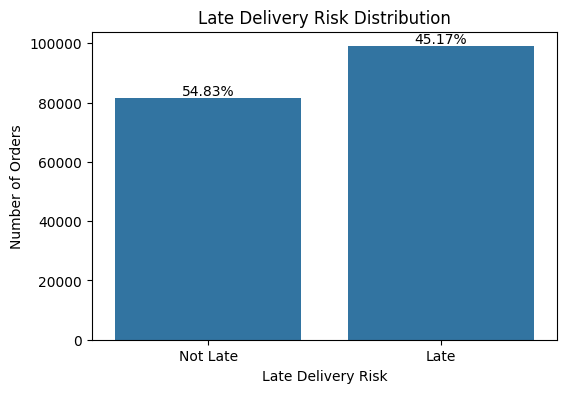

In [70]:
#calculate distribution of late and non-late delivery
target_percentage = df['Late_delivery_risk'].value_counts(normalize=True).mul(100)

print("Late Delivery Risk Percentage:")
print(target_percentage.rename(index={0: 'Not Late', 1: 'Late'}).round(2))

#plot the distribution
plt.figure(figsize=(6,4))
ax = sns.countplot(x='Late_delivery_risk',data=df)
plt.title('Late Delivery Risk Distribution')
plt.xlabel('Late Delivery Risk')
plt.ylabel('Number of Orders')
plt.xticks([0, 1], ['Not Late', 'Late'])



for bar,value in zip(ax.patches,target_percentage.values):
    ax.text(
        bar.get_x() + bar.get_width() /2,
        bar.get_height(),
        f'{value:.2f}%',
        ha='center',
        va='bottom'
    )
plt.show()

**Insight:** The dataset has a slightly higher proportion of late deliveries (54.83%) than non-late deliveries (45.17%), indicating a mild class imbalance.

**Question:** Does the scheduled shipping duration have a relationship with late-delivery risk?


Days for shipment (scheduled)
0      9737
1     27814
2     35216
4    107752
Name: count, dtype: int64

Summary:
 Late_delivery_risk             Not late   Late   Total  Late %
Days for shipment (scheduled)                                 
0                                  5283   4454    9737   45.74
1                                  1301  26513   27814   95.32
2                                  8229  26987   35216   76.63
4                                 66729  41023  107752   38.07


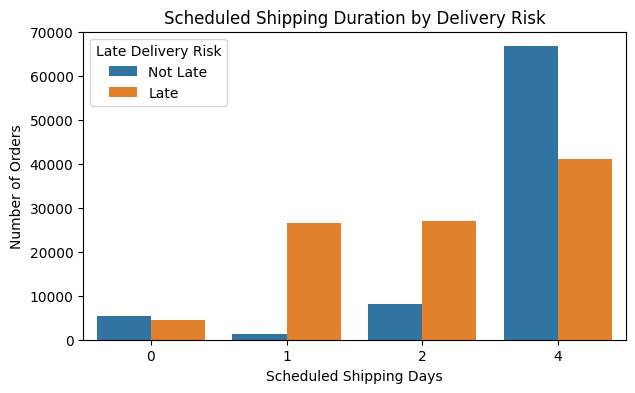

In [71]:
#count days for shipment scheduled
print(df['Days for shipment (scheduled)'].value_counts().sort_index())

#Summary 
summary = pd.crosstab(df['Days for shipment (scheduled)'],df['Late_delivery_risk']).rename(columns={0:"Not late" , 1:"Late"})
summary['Total'] = summary.sum(axis=1)
summary['Late %'] = np.round((summary['Late'] *100 / summary['Total']),2)
print("\nSummary:\n",summary)


#visualization
plt.figure(figsize=(7,4))

sns.countplot(x='Days for shipment (scheduled)',hue='Late_delivery_risk',data=df)
plt.title('Scheduled Shipping Duration by Delivery Risk')
plt.xlabel('Scheduled Shipping Days')
plt.ylabel('Number of Orders')
plt.legend(title='Late Delivery Risk',
           labels=['Not Late', 'Late'])

plt.show()


**Insight:** Scheduled shipping duration shows a strong association with late-delivery risk, with 1–2 day shipments having substantially higher late-delivery rates than same-day and 4-day shipments.

**Question:** Does the quantity of items in an order have a relationship with late-delivery risk?

Late_delivery_risk       0      1
Order Item Quantity              
1                    44729  54405
2                     9276  11039
3                     9134  11216
4                     9188  11147
5                     9215  11170

 Order Item Quantity
1    54.88
2    54.34
3    55.12
4    54.82
5    54.80
Name: Late_delivery_risk, dtype: float64


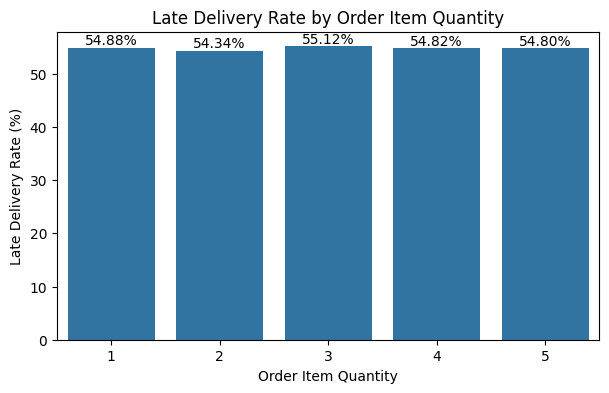

In [72]:
#count late and non-late delivery with order item quantity
print(df.groupby('Order Item Quantity')['Late_delivery_risk'].value_counts().unstack(fill_value=0))

#calculate risk delivery percentage
quantity_risk = df.groupby('Order Item Quantity')['Late_delivery_risk'].mean().mul(100)

print("\n",round(quantity_risk,2))

#visualization
plt.figure(figsize=(7, 4))

ax = sns.barplot(
    x=quantity_risk.index,
    y=quantity_risk.values
)

plt.title('Late Delivery Rate by Order Item Quantity')
plt.xlabel('Order Item Quantity')
plt.ylabel('Late Delivery Rate (%)')

for bar, value in zip(ax.patches, quantity_risk.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.2f}%',
        ha='center',
        va='bottom'
    )

plt.show()


**Insight:** Late-delivery rates remain nearly constant across different order quantities (54.34%–55.12%), suggesting that order item quantity has little association with late-delivery risk.

**Question:** Does the sales value of an order have a relationship with late-delivery risk?

count    180519.000000
mean        203.772096
std         132.273077
min           9.990000
25%         119.980003
50%         199.919998
75%         299.950012
max        1999.989990
Name: Sales, dtype: float64
Sales
Very Low     55.25
Low          54.69
Medium       54.75
High         54.60
Very High    54.87
Name: Late_delivery_risk, dtype: float64


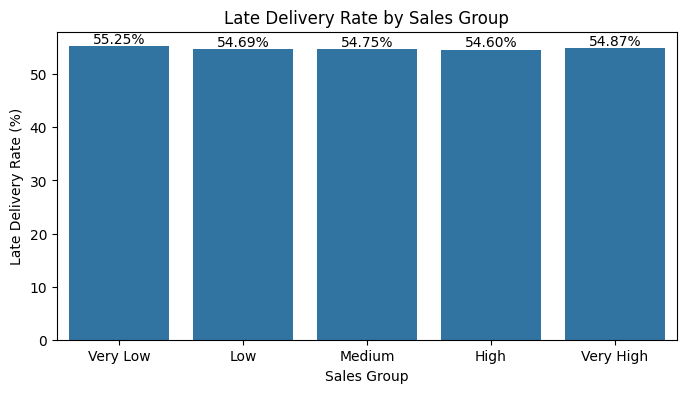

In [73]:
#checking distribution
print(df['Sales'].describe())

#divide into groups
Sales_Group = pd.qcut(
    df['Sales'],
    q=5,
    labels=['Very Low', 'Low', 'Medium', 'High', 'Very High']
)

sales_risk = (
    df.groupby(Sales_Group,observed=True)['Late_delivery_risk'].mean().mul(100)
)

print(sales_risk.round(2))

#visualize
plt.figure(figsize=(8, 4))

ax = sns.barplot(
    x=sales_risk.index,
    y=sales_risk.values
)

plt.title('Late Delivery Rate by Sales Group')
plt.xlabel('Sales Group')
plt.ylabel('Late Delivery Rate (%)')

for bar, value in zip(ax.patches, sales_risk.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.2f}%',
        ha='center',
        va='bottom'
    )

plt.show()

**Insight:** Late-delivery rates remain nearly constant across sales groups (54.60%–55.25%), suggesting that sales value has little association with late-delivery risk.

**Question:** Does the shipping mode have a relationship with late-delivery risk?

Late_delivery_risk      0      1
Shipping Mode                   
First Class          1301  26513
Same Day             5283   4454
Second Class         8229  26987
Standard Class      66729  41023
Shipping Mode
First Class       95.32
Same Day          45.74
Second Class      76.63
Standard Class    38.07
Name: Late_delivery_risk, dtype: float64


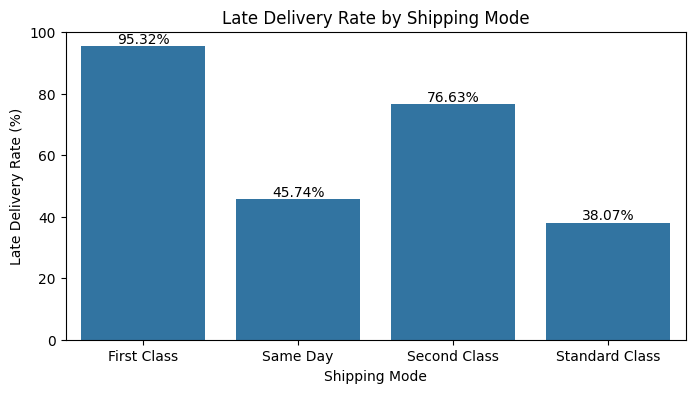

In [74]:
#count late and non-late deliveries
print(df.groupby('Shipping Mode')['Late_delivery_risk'].value_counts().unstack(fill_value=0))

#calculate late delivery percentage
shipping_risk = (
    df.groupby('Shipping Mode')['Late_delivery_risk']
    .mean()
    .mul(100)
)

print(shipping_risk.round(2))

#visualization
plt.figure(figsize=(8, 4))

ax = sns.barplot(
    x=shipping_risk.index,
    y=shipping_risk.values
)

plt.title('Late Delivery Rate by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Late Delivery Rate (%)')

for bar, value in zip(ax.patches, shipping_risk.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.2f}%',
        ha='center',
        va='bottom'
    )

plt.show()

**Insight:** Shipping mode shows a strong association with late-delivery risk, with late-delivery rates ranging from 38.07% for Standard Class to 95.32% for First Class. However, shipping mode is closely related to scheduled shipping duration, so their overlapping information should be considered during feature engineering.

**Question:** Does the customer segment have a relationship with late-delivery risk?

Late_delivery_risk      0      1
Customer Segment                
Consumer            42256  51248
Corporate           24807  29982
Home Office         14479  17747
Customer Segment
Consumer       54.81
Corporate      54.72
Home Office    55.07
Name: Late_delivery_risk, dtype: float64


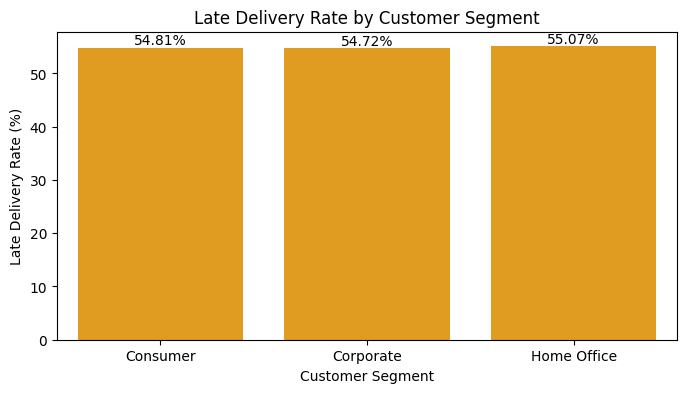

In [75]:
#count late and non-late deliveries
print(df.groupby('Customer Segment')['Late_delivery_risk'].value_counts().unstack(fill_value=0))

#calculate late delivery rate
customer_segment_risk = (
    df.groupby('Customer Segment')['Late_delivery_risk']
    .mean()
    .mul(100)
)

print(customer_segment_risk.round(2))

#visualize the result
plt.figure(figsize=(8, 4))

ax = sns.barplot(
    x=customer_segment_risk.index,
    y=customer_segment_risk.values,
    color='orange'
)

plt.title('Late Delivery Rate by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Late Delivery Rate (%)')

for bar, value in zip(ax.patches, customer_segment_risk.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.2f}%',
        ha='center',
        va='bottom'
    )

plt.show()

**Insight:** Late-delivery rates are nearly identical across customer segments (54.72%–55.07%), suggesting that customer segment has little association with late-delivery risk.

**Question:** Does the market have a relationship with late-delivery risk?

Late_delivery_risk      0      1
Market                          
Africa               5274   6340
Europe              22509  27743
LATAM               23550  28044
Pacific Asia        18548  22712
USCA                11661  14138
Market
Africa          54.59
Europe          55.21
LATAM           54.36
Pacific Asia    55.05
USCA            54.80
Name: Late_delivery_risk, dtype: float64


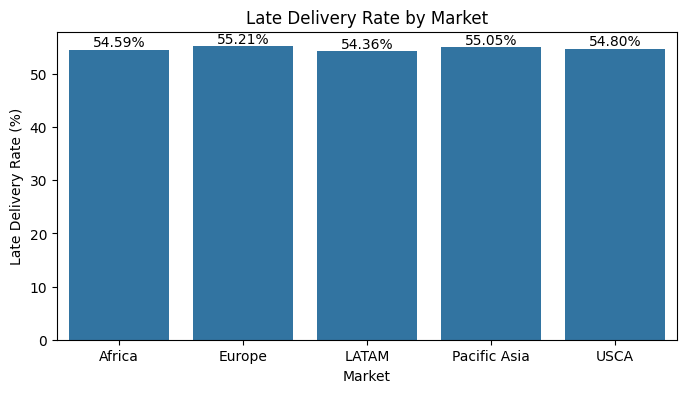

In [76]:
#count
print(df.groupby('Market')['Late_delivery_risk'].value_counts().unstack(fill_value=0))

#late delivery rate
market_risk = (
    df.groupby('Market')['Late_delivery_risk']
    .mean()
    .mul(100)
)

print(market_risk.round(2))

#plot
plt.figure(figsize=(8, 4))

ax = sns.barplot(
    x=market_risk.index,
    y=market_risk.values
)

plt.title('Late Delivery Rate by Market')
plt.xlabel('Market')
plt.ylabel('Late Delivery Rate (%)')

for bar, value in zip(ax.patches, market_risk.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.2f}%',
        ha='center',
        va='bottom'
    )

plt.show()


**Insight:** Late-delivery rates are very similar across markets (54.36%–55.21%), suggesting that market has little standalone association with late-delivery risk.

**Question:** Does the order region have a relationship with late-delivery risk?

Late_delivery_risk      0      1
Order Region                    
Canada                491    468
Caribbean            3903   4415
Central Africa        705    972
Central America     12823  15518
Central Asia          247    306
East Africa           816   1036
East of USA          3066   3849
Eastern Asia         3325   3955
Eastern Europe       1738   2182
North Africa         1470   1762
Northern Europe      4500   5292
Oceania              4666   5482
South America        6824   8111
South Asia           3381   4350
South of USA         1789   2256
Southeast Asia       4242   5297
Southern Africa       540    617
Southern Europe      4302   5129
US Center            2635   3252
West Africa          1743   1953
West Asia            2687   3322
West of USA          3680   4313
Western Europe      11969  15140
Order Region
Central Africa     57.96
South Asia         56.27
East Africa        55.94
Western Europe     55.85
South of USA       55.77
Eastern Europe     55.66
East of USA 

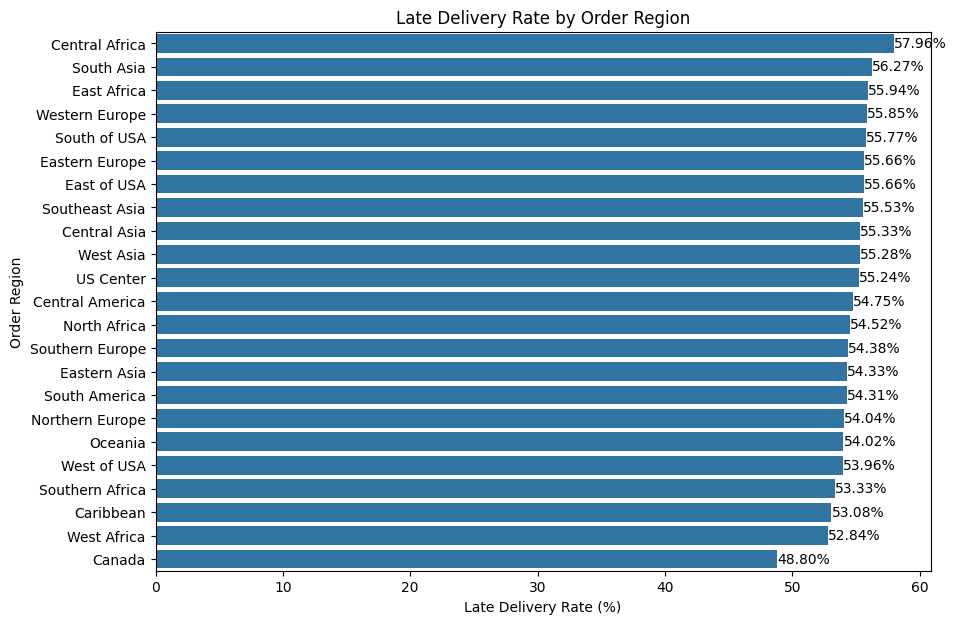

In [77]:
#count
print(df.groupby('Order Region')['Late_delivery_risk'].value_counts().unstack(fill_value=0))

#late delivery rate
region_risk = (
    df.groupby('Order Region')['Late_delivery_risk']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(region_risk.round(2))

#visualization
plt.figure(figsize=(10, 7))

ax = sns.barplot(
    x=region_risk.values,
    y=region_risk.index
)

plt.title('Late Delivery Rate by Order Region')
plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Order Region')

for bar, value in zip(ax.patches, region_risk.values):
    ax.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.2f}%',
        ha='left',
        va='center'
    )

plt.show()

**Insight:** Late-delivery rates vary across order regions from 48.80% to 57.96%, indicating that order region has some association with late-delivery risk and may provide useful geographic information for prediction.

**Question :** Does customer country have a relationship with late-delivery risk?

In [78]:
#Number of late/non-late deliveries by country
customer_country_counts = (
    df.groupby('Customer Country')['Late_delivery_risk']
    .value_counts()
    .unstack(fill_value=0)
)

print(customer_country_counts)

#Late-delivery rate by country
customer_country_risk = (
    df.groupby('Customer Country')['Late_delivery_risk']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(customer_country_risk.round(2))

Late_delivery_risk      0      1
Customer Country                
EE. UU.             50160  60986
Puerto Rico         31382  37991
Customer Country
EE. UU.        54.87
Puerto Rico    54.76
Name: Late_delivery_risk, dtype: float64


**Insight:** Late-delivery rates are nearly identical across customer countries (54.76%–54.87%), suggesting that customer country has little standalone association with late-delivery risk.

**Question:** Does order country have a relationship with late-delivery risk?

In [79]:
order_country_counts = (
    df.groupby('Order Country')['Late_delivery_risk']
    .value_counts()
    .unstack(fill_value=0)
)


print(order_country_counts.round(2).to_string())


order_country_risk = (
    df.groupby('Order Country')['Late_delivery_risk']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(order_country_risk.round(2).to_string())


Late_delivery_risk                   0      1
Order Country                                
Afganistán                          70     93
Albania                             15     22
Alemania                          4181   5383
Angola                             123    183
Arabia Saudí                       364    496
Argelia                            242    274
Argentina                          932    999
Armenia                              0      5
Australia                         3884   4613
Austria                            581    806
Azerbaiyán                          29     39
Bangladés                          192    274
Barbados                            52     65
Baréin                               4      0
Belice                               5      8
Benín                               46     39
Bielorrusia                        103    107
Bolivia                             87    126
Bosnia y Herzegovina                14     31
Botsuana                          

**Insight:** Late-delivery rates vary considerably across order countries, but extreme rates are often associated with countries having very few orders. Therefore, country-level differences should be interpreted alongside order volume, while geographic information may still provide useful predictive information.

**Question:** Does product category have a relationship with late-delivery risk?

In [80]:
#count
category_counts = (
    df.groupby('Category Name')['Late_delivery_risk']
    .value_counts()
    .unstack(fill_value=0)
)

print(category_counts)

#late delivery rate
category_risk = (
    df.groupby('Category Name')['Late_delivery_risk']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(category_risk.round(2))

Late_delivery_risk        0      1
Category Name                     
Accessories             766   1014
As Seen on TV!           29     39
Baby                     98    109
Baseball & Softball     283    349
Basketball               30     37
Books                   176    229
Boxing & MMA            185    238
CDs                     130    141
Cameras                 248    344
Camping & Hiking       6242   7487
Cardio Equipment       5682   6805
Children's Clothing     304    348
Cleats                11055  13496
Computers               218    224
Consumer Electronics    193    238
Crafts                  213    271
DVDs                    224    259
Electronics            1386   1770
Fishing                7809   9516
Fitness Accessories     133    176
Garden                  214    270
Girls' Apparel          537    664
Golf Apparel            212    229
Golf Bags & Carts        19     42
Golf Balls              670    805
Golf Gloves             468    602
Golf Shoes          

**Insight:** Late-delivery rates vary across product categories, ranging from 47.70% to 68.85%, indicating that product category may have some association with late-delivery risk. However, categories with small order volumes should be interpreted cautiously.

**Question:** Does department have a relationship with late-delivery risk?

In [81]:
#Late/non-late counts
department_counts = (
    df.groupby('Department Name')['Late_delivery_risk']
    .value_counts()
    .unstack(fill_value=0)
)

print(department_counts)

#Late-delivery rate
department_risk = (
    df.groupby('Department Name')['Late_delivery_risk']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(department_risk.round(2))

Late_delivery_risk      0      1
Department Name                 
Apparel             22173  26825
Book Shop             176    229
Discs Shop            923   1103
Fan Shop            30238  36623
Fitness              1102   1377
Footwear             6576   7949
Golf                15022  18198
Health and Beauty     160    202
Outdoors             4311   5375
Pet Shop              202    290
Technology            659    806
Department Name
Pet Shop             58.94
Book Shop            56.54
Health and Beauty    55.80
Fitness              55.55
Outdoors             55.49
Technology           55.02
Golf                 54.78
Fan Shop             54.77
Apparel              54.75
Footwear             54.73
Discs Shop           54.44
Name: Late_delivery_risk, dtype: float64


**Insight:** Late-delivery rates vary only moderately across departments (54.44%–58.94%), suggesting that department has a relatively weak standalone association with late-delivery risk.

**Question:** Does the order item discount have a relationship with late-delivery risk?

In [82]:
#Discount statistics
print(df['Order Item Discount'].describe())


#compare discount with late delivery risk column
discount_group = pd.qcut(
    df['Order Item Discount'],
    q=5,
    labels=['Very Low', 'Low', 'Medium', 'High', 'Very High']
)

discount_risk = (
    df.groupby(discount_group,observed=True)['Late_delivery_risk']
    .mean()
    .mul(100)
)

print(discount_risk.round(2))

count    180519.000000
mean         20.664741
std          21.800901
min           0.000000
25%           5.400000
50%          14.000000
75%          29.990000
max         500.000000
Name: Order Item Discount, dtype: float64
Order Item Discount
Very Low     55.14
Low          54.86
Medium       54.56
High         54.46
Very High    55.10
Name: Late_delivery_risk, dtype: float64


**Insight:** Late-delivery rates remain nearly constant across discount groups (54.46%–55.14%), suggesting that discount has little standalone association with late-delivery risk.

**Question:** Does the month in which an order is placed have a relationship with late-delivery risk?

order date (DateOrders)
1     54.66
2     54.55
3     55.25
4     54.28
5     54.74
6     54.83
7     54.06
8     55.79
9     55.30
10    54.60
11    54.55
12    55.34
Name: Late_delivery_risk, dtype: float64


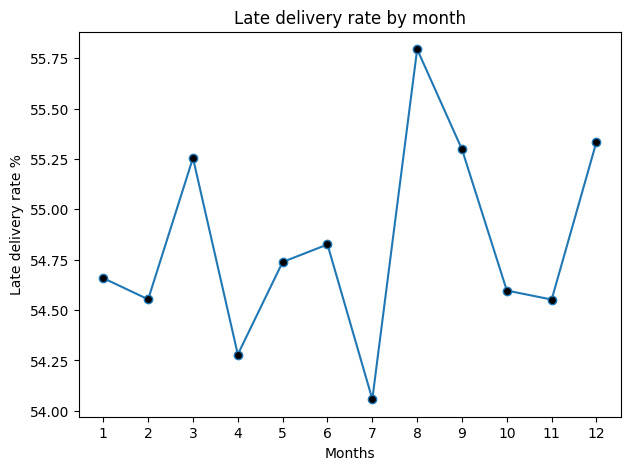

In [110]:
#late delivery rate by month
monthly_risk = (
    df.groupby(
        df['order date (DateOrders)'].dt.month
    )['Late_delivery_risk']
    .mean()
    .mul(100)
)

print(monthly_risk.round(2))

plt.figure(figsize=(7,5))
plt.plot(monthly_risk.index,monthly_risk.values,marker='o',markerfacecolor='black')
plt.title('Late delivery rate by month')
plt.xlabel("Months")
plt.ylabel("Late delivery rate %")
plt.xticks(range(1,13))
plt.show()


**Insight:** Late-delivery rates remain relatively stable across months (54.06%–55.79%), suggesting that the month of order placement has little standalone association with late-delivery risk.

**Question:** Does the day of the week on which an order is placed have a relationship with late-delivery risk?

order date (DateOrders)
Monday       55.05
Tuesday      54.30
Wednesday    54.76
Thursday     55.01
Friday       55.17
Saturday     54.40
Sunday       55.11
Name: Late_delivery_risk, dtype: float64


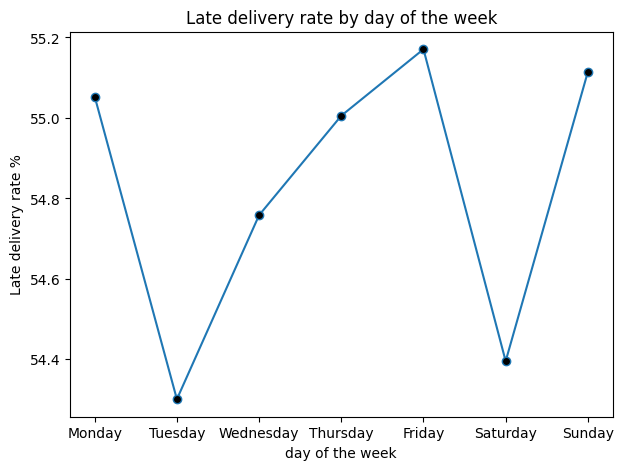

In [115]:
weekday_risk = (
    df.groupby(
        df['order date (DateOrders)'].dt.day_name()
    )['Late_delivery_risk']
    .mean()
    .mul(100)
)

# Arrange days in calendar order
weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekday_risk = weekday_risk.reindex(weekday_order)

print(weekday_risk.round(2))

plt.figure(figsize=(7,5))
plt.plot(weekday_risk.index,weekday_risk.values,marker='o',markerfacecolor='black')
plt.title('Late delivery rate by day of the week')
plt.xlabel("day of the week")
plt.ylabel("Late delivery rate %")
plt.show()

**Insight:** Late-delivery rates remain relatively stable across days of the week (54.30%–55.17%), suggesting that the day of order placement has little standalone association with late-delivery risk.

**Question:** Does the year in which an order is placed have a relationship with late-delivery risk?

order date (DateOrders)
2015    54.86
2016    55.07
2017    54.45
2018    56.29
Name: Late_delivery_risk, dtype: float64


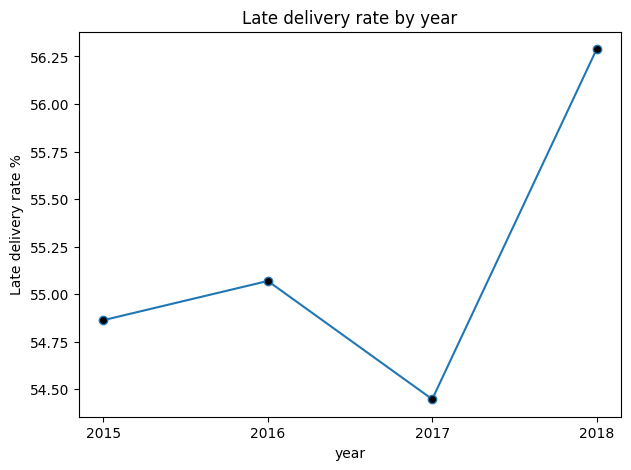

In [114]:
yearly_risk = (
    df.groupby(
        df['order date (DateOrders)'].dt.year
    )['Late_delivery_risk']
    .mean()
    .mul(100)
)

print(yearly_risk.round(2))

plt.figure(figsize=(7,5))
plt.plot(yearly_risk.index,yearly_risk.values,marker='o',markerfacecolor='black')
plt.title('Late delivery rate by year')
plt.xlabel("year")
plt.ylabel("Late delivery rate %")
plt.xticks([2015,2016,2017,2018])
plt.show()


In [120]:
#analysis based on year
year_counts = (
    df['order date (DateOrders)']
    .dt.year
    .value_counts()
    .sort_index()
)

print(year_counts)

order date (DateOrders)
2015    62650
2016    62550
2017    53196
2018     2123
Name: count, dtype: int64


**Insight:** Late-delivery rates remain relatively stable across the major years (54.45%–55.07%), while 2018 shows a somewhat higher rate of 56.29% but contains only 2,123 orders. Overall, year of order placement shows little standalone association with late-delivery risk, and the 2018 difference should be interpreted cautiously due to its smaller sample size.

**Question:** Which numerical features show a relationship with late-delivery risk?

In [123]:
numerical_cols = df.select_dtypes(include='number').columns

correlation_with_target = (
    df[numerical_cols]
    .corr()['Late_delivery_risk']
    .sort_values(ascending=False)
)

print(correlation_with_target.round(3))


Late_delivery_risk               1.000
Customer Zipcode                 0.003
Category Id                      0.002
Product Card Id                  0.001
Customer Id                      0.001
Department Id                    0.001
Latitude                         0.001
Order Item Discount Rate         0.000
Order Item Quantity             -0.000
Order Item Discount             -0.001
Order Item Id                   -0.001
Longitude                       -0.002
Product Price                   -0.002
Sales                           -0.004
Order Item Total                -0.004
Days for shipment (scheduled)   -0.369
Name: Late_delivery_risk, dtype: float64


**Insight:** Among the numerical features, scheduled shipping duration shows the strongest relationship with late-delivery risk, with a correlation of -0.369. Most other numerical variables have correlations close to zero, indicating little linear association with late-delivery risk. The negative correlation for scheduled shipping duration is consistent with the earlier finding that different scheduled durations have substantially different late-delivery rates.

**Question:** Are there strongly correlated numerical features that may contain redundant information?

In [128]:
numerical_data = df.select_dtypes(include='number')

correlation_matrix = numerical_data.corr()

print(correlation_matrix.round(2))

corr_pairs = (
    correlation_matrix
    .where(
        ~np.eye(correlation_matrix.shape[0], dtype=bool)
    )
    .stack()
    .sort_values(ascending=False)
)

print(corr_pairs.head(20))

                               Days for shipment (scheduled)  \
Days for shipment (scheduled)                           1.00   
Late_delivery_risk                                     -0.37   
Category Id                                            -0.00   
Customer Id                                             0.00   
Customer Zipcode                                       -0.00   
Department Id                                          -0.00   
Latitude                                               -0.01   
Longitude                                               0.00   
Order Item Discount                                     0.00   
Order Item Discount Rate                                0.00   
Order Item Id                                          -0.00   
Order Item Quantity                                    -0.00   
Sales                                                   0.01   
Order Item Total                                        0.01   
Product Card Id                         

**Insight:** Several numerical feature pairs show strong correlations, particularly Category Id and Product Card Id (0.99), Sales and Order Item Total (0.99), and Product Card Id and Department Id (0.91). These relationships indicate potential redundancy or shared information among some numerical features. However, correlation alone should not determine feature removal, especially for identifier-like and categorical variables.

**Question:** Are there redundant, derived, or identifier-like features that should be considered before machine learning?

In [129]:
# Find columns that contain exactly the same values

duplicate_columns = []

columns = df.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        if df[columns[i]].equals(df[columns[j]]):
            duplicate_columns.append((columns[i], columns[j]))

duplicate_columns

[]

In [130]:
df.columns.tolist()

['Type',
 'Days for shipment (scheduled)',
 'Late_delivery_risk',
 'Category Id',
 'Category Name',
 'Customer City',
 'Customer Country',
 'Customer Id',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Customer Zipcode',
 'Department Id',
 'Department Name',
 'Latitude',
 'Longitude',
 'Market',
 'Order City',
 'Order Country',
 'order date (DateOrders)',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Region',
 'Order State',
 'Product Card Id',
 'Product Name',
 'Product Price',
 'Shipping Mode']

In [133]:
for col in df.columns:
    if df[col].dtype != 'object':
        print(
            f"{col:<35} "
            f"Unique: {df[col].nunique():>8} "
            f"Rows: {len(df):>8}"
        )

Days for shipment (scheduled)       Unique:        4 Rows:   180519
Late_delivery_risk                  Unique:        2 Rows:   180519
Category Id                         Unique:       51 Rows:   180519
Customer Id                         Unique:    20652 Rows:   180519
Customer Zipcode                    Unique:      995 Rows:   180519
Department Id                       Unique:       11 Rows:   180519
Latitude                            Unique:    11250 Rows:   180519
Longitude                           Unique:     4487 Rows:   180519
order date (DateOrders)             Unique:    65752 Rows:   180519
Order Item Discount                 Unique:     1017 Rows:   180519
Order Item Discount Rate            Unique:       18 Rows:   180519
Order Item Id                       Unique:   180519 Rows:   180519
Order Item Quantity                 Unique:        5 Rows:   180519
Sales                               Unique:      193 Rows:   180519
Order Item Total                    Unique:     

In [135]:
checks = {
    'Sales = Order Item Total':
        df['Sales'].equals(df['Order Item Total']),

    'Category Id = Product Card Id':
        df['Category Id'].equals(df['Product Card Id']),

    'Category Id = Department Id':
        df['Category Id'].equals(df['Department Id']),

    'Product Card Id = Department Id':
        df['Product Card Id'].equals(df['Department Id']),

    'Product Price = Sales':
        df['Product Price'].equals(df['Sales'])
}

for relationship, result in checks.items():
    print(f"{relationship}: {result}")

Sales = Order Item Total: False
Category Id = Product Card Id: False
Category Id = Department Id: False
Product Card Id = Department Id: False
Product Price = Sales: False


In [137]:
comparison = pd.DataFrame({
    'Sales': df['Sales'],
    'Order Item Total': df['Order Item Total']
})

comparison['Difference'] = (
    comparison['Sales'] - comparison['Order Item Total']
)

print(comparison['Difference'].describe())

print((comparison['Difference'] == 0).mean() * 100)

count    180519.000000
mean         20.664488
std          21.800525
min           0.000000
25%           5.400002
50%          14.000000
75%          29.990005
max         500.000000
Name: Difference, dtype: float64
5.555093923631308


In [140]:
difference_check = (
    df['Sales']
    - df['Order Item Discount']
    - df['Order Item Total']
)

print(difference_check.describe())


print((difference_check.abs() < 0.01).mean() * 100)

count    180519.000000
mean         -0.000254
std           0.001577
min          -0.010014
25%           0.000000
50%           0.000000
75%           0.000004
max           0.000042
dtype: float64
99.32195502966447


In [142]:
product_mapping = (
    df.groupby('Product Card Id')
      .agg(
          unique_categories=('Category Id', 'nunique'),
          unique_departments=('Department Id', 'nunique')
      )
)

print(product_mapping.describe())


print(
    "Products mapped to multiple categories:",
    (product_mapping['unique_categories'] > 1).sum()
)

print(
    "Products mapped to multiple departments:",
    (product_mapping['unique_departments'] > 1).sum()
)

       unique_categories  unique_departments
count              118.0               118.0
mean                 1.0                 1.0
std                  0.0                 0.0
min                  1.0                 1.0
25%                  1.0                 1.0
50%                  1.0                 1.0
75%                  1.0                 1.0
max                  1.0                 1.0
Products mapped to multiple categories: 0
Products mapped to multiple departments: 0


**Insight:** The analysis identified several relationships among the remaining features. Order Item Total is approximately derived from Sales and Order Item Discount, with 99.32% of rows matching the relationship within 0.01. Product Card Id maps uniquely to one Category Id and one Department Id, explaining the strong correlations among these product hierarchy variables. Order Item Id is a row-level identifier with a unique value for every record and should not be used as a predictive feature. These findings will be considered during feature engineering rather than removing features based solely on correlation.

**Question:** What are the key patterns and relationships identified during the exploratory data analysis?

**Insight:** <br>
The EDA identified several important patterns in the dataset. **Scheduled shipping duration** and **shipping mode** show the strongest association with **late-delivery risk**, while **order region and product category** show moderate variation in late-delivery rates. Variables such as **order quantity, sales, discount, customer segment, market, department, and calendar-based features** show relatively weak standalone associations. The analysis also identified several redundant or derived features, including the strong relationship between product hierarchy variables and the approximate relationship between **Order Item Total, Sales, and Order Item Discount.** These findings will guide feature engineering and model development while avoiding decisions based solely on correlation or standalone EDA results.

**Question:** Which features should be kept, removed, or transformed based on the EDA findings and prediction-time requirements?

In [143]:
initial_features = [
    'Type',
    'Days for shipment (scheduled)',
    'Category Id',
    'Customer City',
    'Customer Country',
    'Customer Segment',
    'Customer State',
    'Customer Zipcode',
    'Latitude',
    'Longitude',
    'Market',
    'Order City',
    'Order Country',
    'Order Region',
    'Order State',
    'Product Card Id',
    'Product Price',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Quantity',
    'Sales'
]

**Insight:** The EDA findings and prediction-time analysis provide a foundation for feature selection. Identifier-like columns such as **Order Item Id, Customer Id, and Customer Street** will be excluded from the initial model. Redundant representations of shipping mode, product hierarchy, and financial information will be reviewed to avoid unnecessary duplication. The order date will be transformed into calendar features, while geographic and high-cardinality categorical variables will require appropriate handling. Features will not be removed solely because they have weak standalone correlations with the target. The initial feature set will be validated during model development using appropriate evaluation metrics.